# Investigating specificity information in AF3 Scores

In this notebook, we investigate the ability of alphafold3 confidence scores at discriminating between binding and non-binding TCR:pMHC complexes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import ranksums
from sklearn.metrics import roc_auc_score

In [2]:
af3_scores = pd.read_csv('../data/processed/confidence_scores_af3_tcrmodel2_1500.csv')
af3_scores['structure_name'] = af3_scores['structure_name'].astype('str')

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences.index = sequences.index.astype('str')

In [4]:
af3_scores = af3_scores.merge(sequences, left_on='structure_name', right_index=True, how='left')

In [5]:
af3_scores['type'] = af3_scores['label'].map(lambda label: 'binder' if label else 'decoy')

In [6]:
[
    col
    for col in af3_scores.columns
    if 'ptm' not in col and 'pae' not in col and 'ipsae' not in col and 'plddt' not in col
]

['structure_name',
 'seed',
 'sample',
 'fraction_disordered',
 'has_clash',
 'ranking_score',
 'top_model',
 'alphabridge_score',
 'cdr1_alpha',
 'cdr2_alpha',
 'cdr3_alpha',
 'cdr1_beta',
 'cdr2_beta',
 'cdr3_beta',
 'peptide',
 'mhc_pseudo',
 'v_alpha',
 'j_alpha',
 'v_beta',
 'j_beta',
 'mhc1',
 'mhc2',
 'mhc_type',
 'species',
 'source',
 'label',
 'fold',
 'type']

In [7]:
scores_summary = []

for column_name in af3_scores.filter(regex=r'ptm').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

for column_name in af3_scores.filter(regex=r'pae').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = 1 - roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='less',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = 1 - roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='less',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

for column_name in af3_scores.filter(regex=r'plddt').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

for column_name in af3_scores.filter(regex=r'ipsae').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

scores_summary = pd.DataFrame(scores_summary)
scores_summary = scores_summary.set_index('metric')

In [8]:
scores_summary.sort_values('roc_all_models', ascending=False)

,roc_all_models,stat_all_models,p_val_all_models,roc_top_model,stat_top_model,p_val_top_model
metric,,,,,,
combined_ipsaes,0.615853,17.376842,6.178731e-68,0.616194,7.791919,3.299960e-15
antigen_chain_beta_chain_ipsae,0.615192,17.277579,3.470036e-67,0.616969,7.843897,2.183870e-15
antigen_chain_alpha_chain_ipsae,0.613941,17.090061,8.799529e-66,0.615129,7.720508,5.793368e-15
mhc_chain1_beta_chain_ipsae,0.612894,16.932914,1.286602e-64,0.613588,7.617146,1.296727e-14
beta_chain_antigen_chain_ipsae,0.612758,16.912558,1.817893e-64,0.612245,7.527137,2.593243e-14
...,...,...,...,...,...,...
mhc_chain_2_mhc_chain_1_pae_min,0.486298,2.055138,9.800671e-01,0.495808,0.281114,6.106886e-01
mhc_chain_1_mhc_chain_2_pae_min,0.482672,2.598973,9.953248e-01,0.486367,0.914217,8.196987e-01
beta_chain_alpha_chain_pae_min,0.481797,2.730298,9.968361e-01,0.480085,1.335471,9.091389e-01


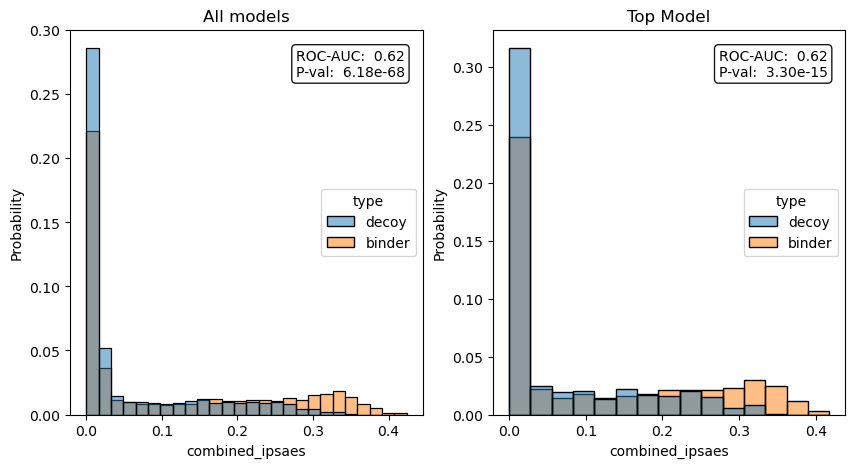

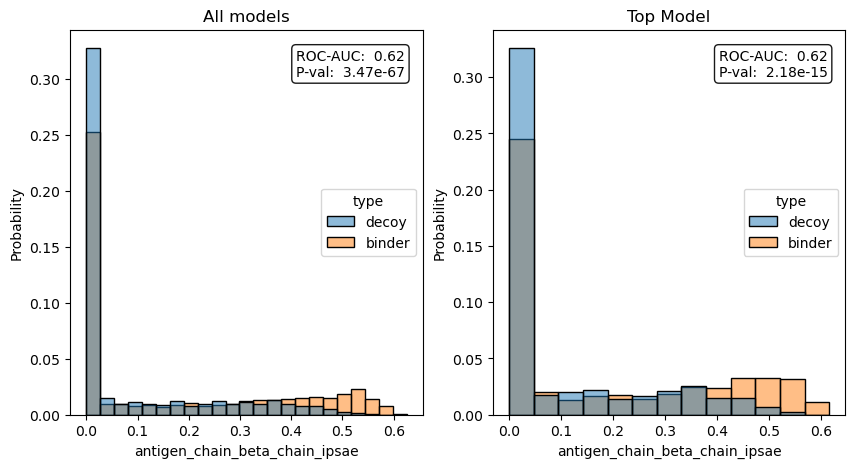

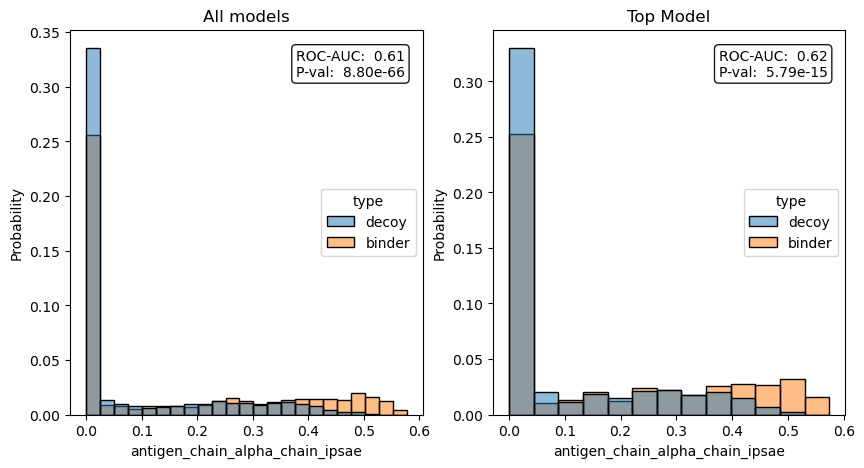

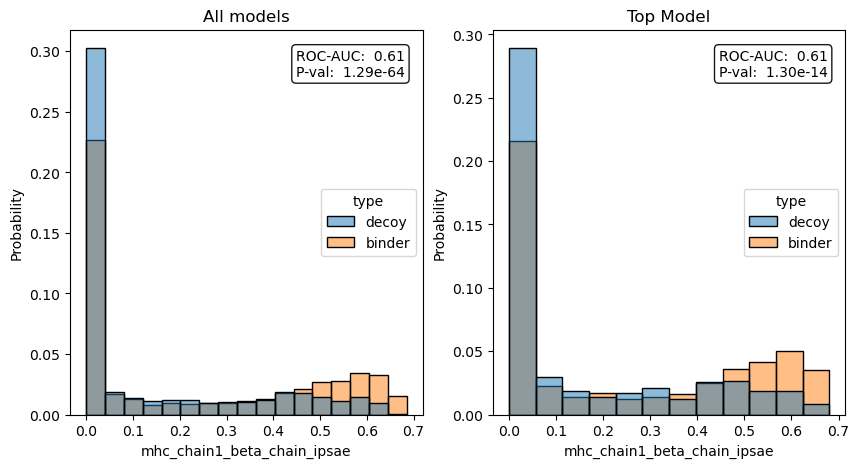

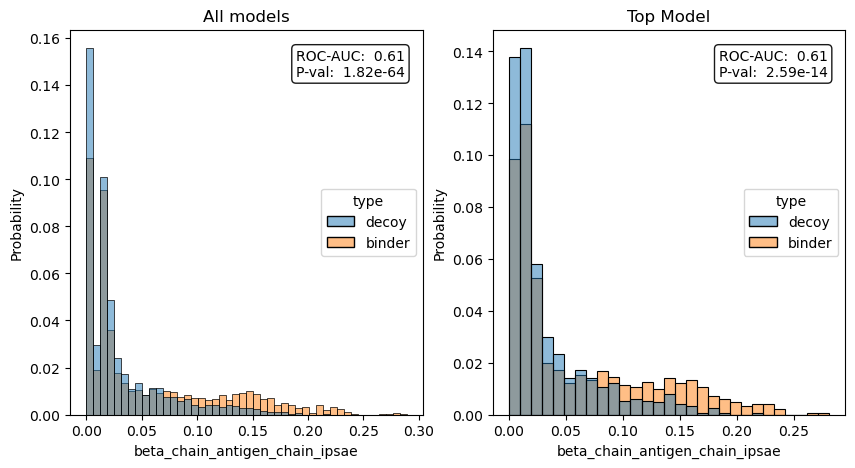

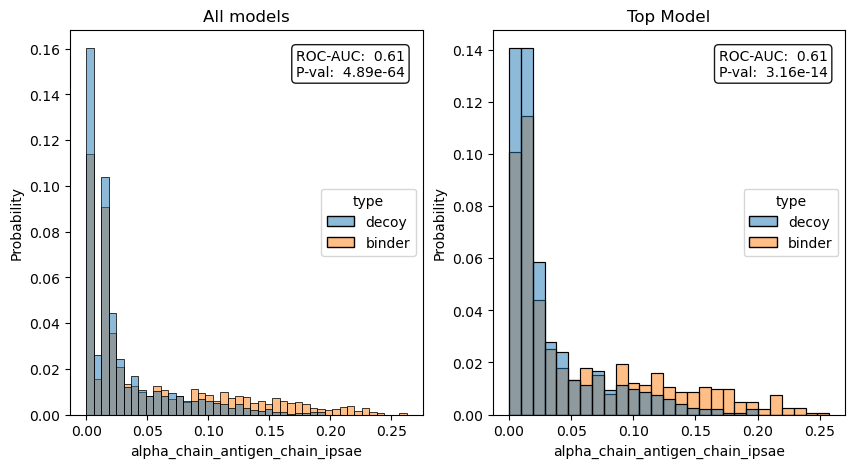

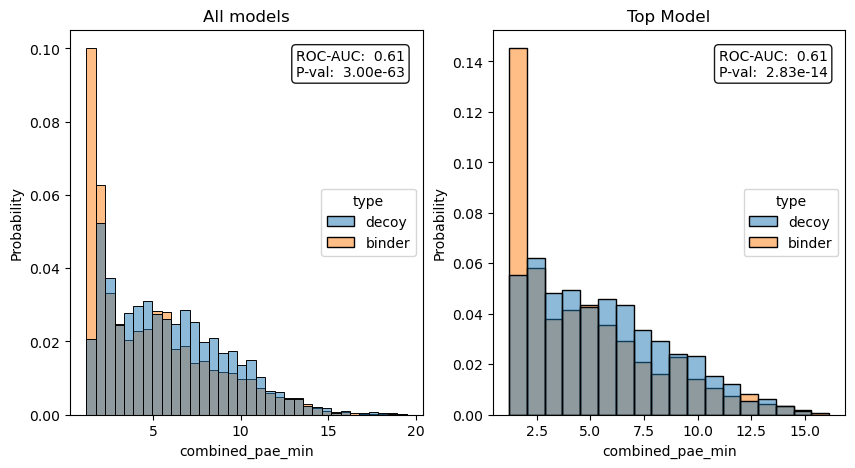

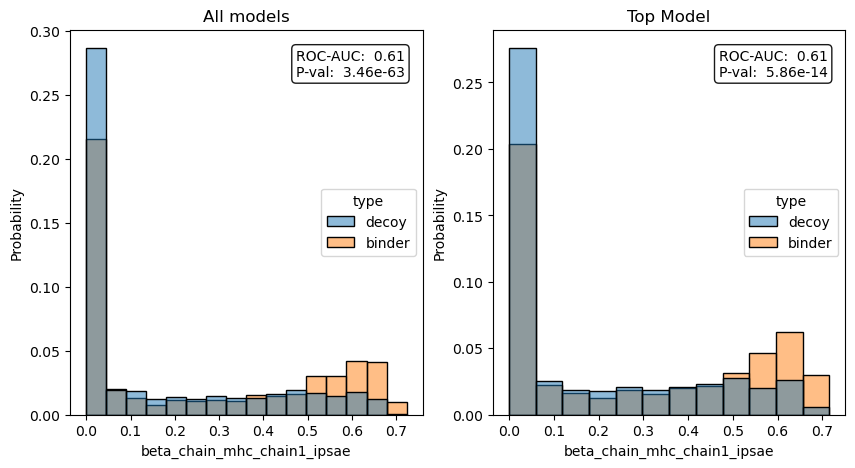

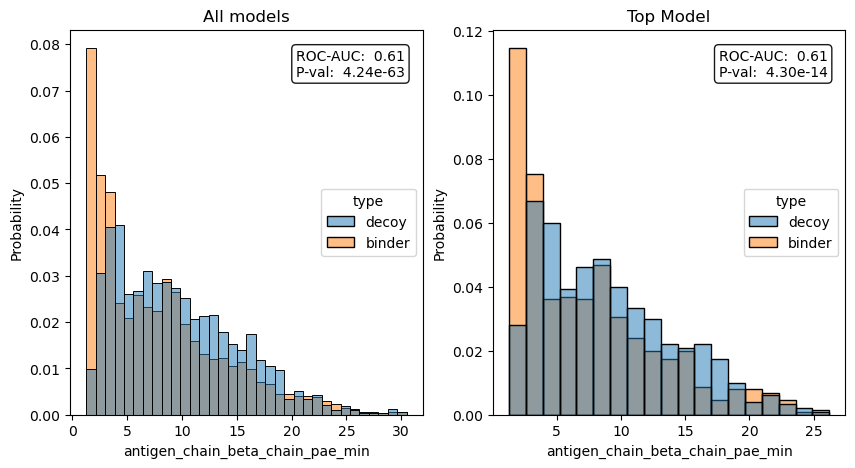

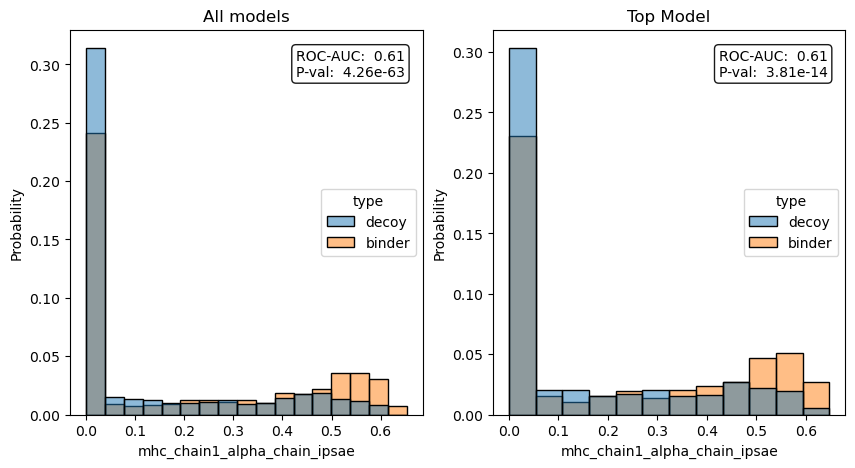

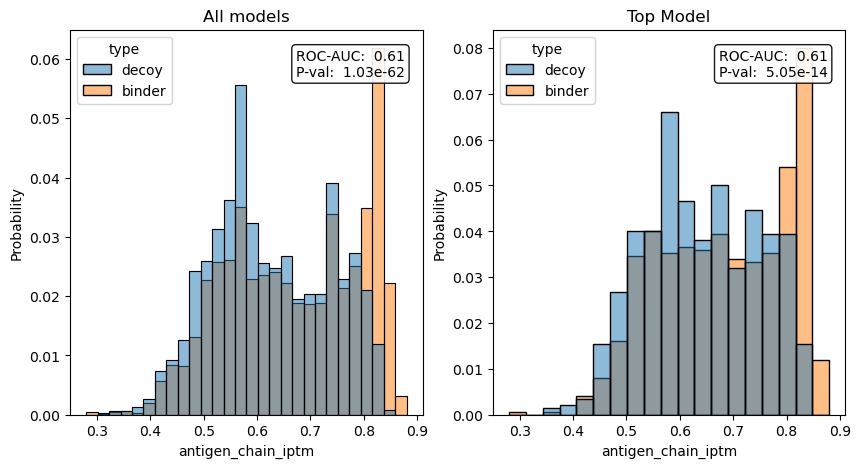

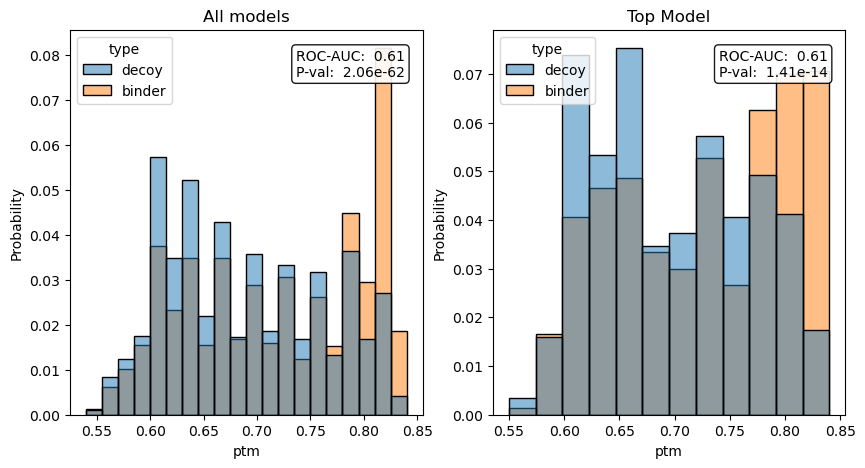

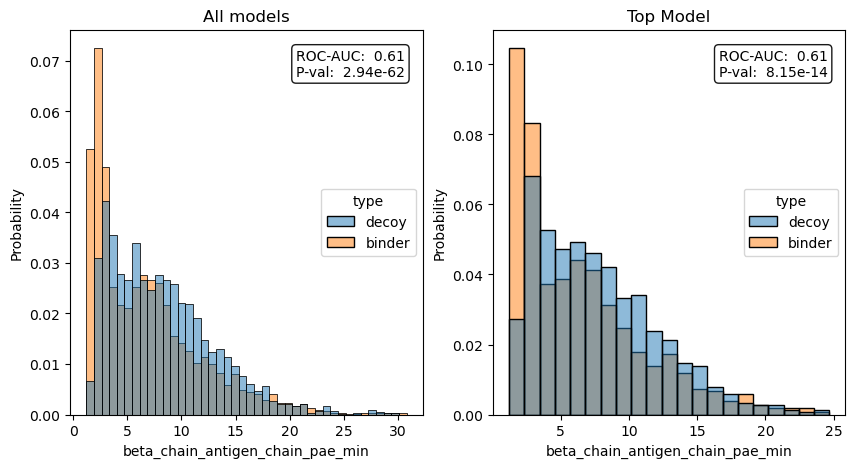

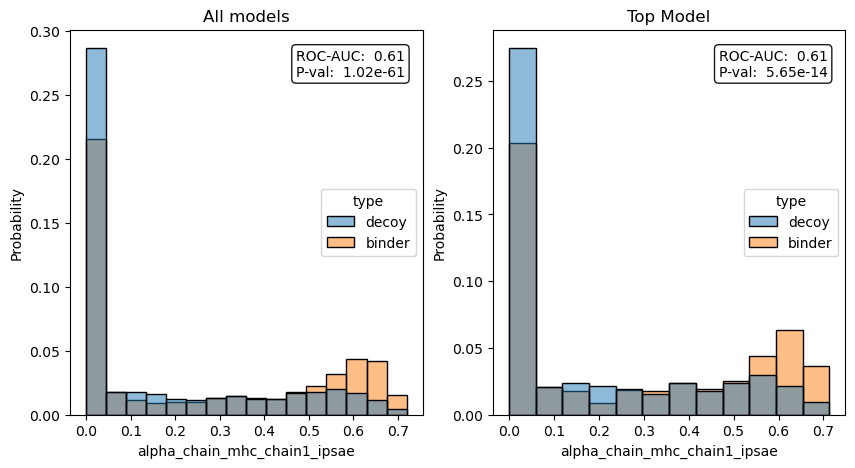

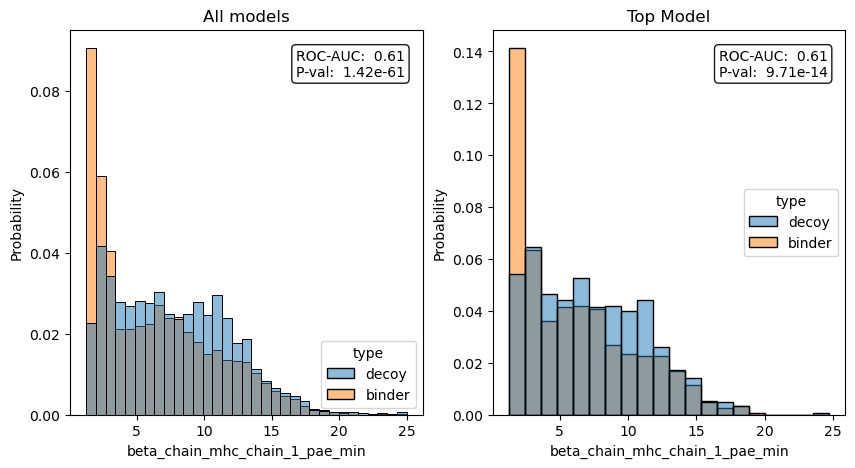

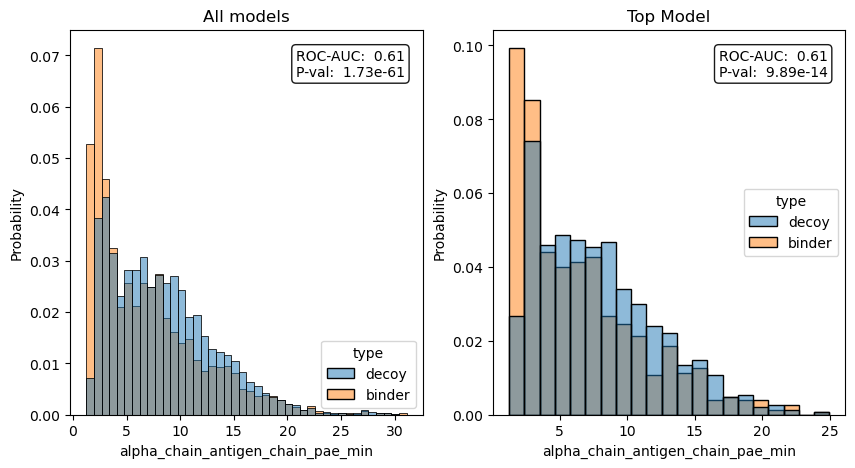

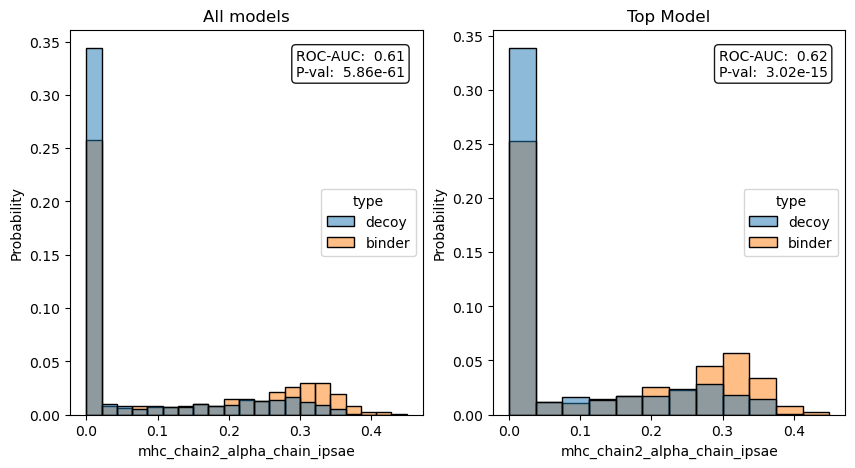

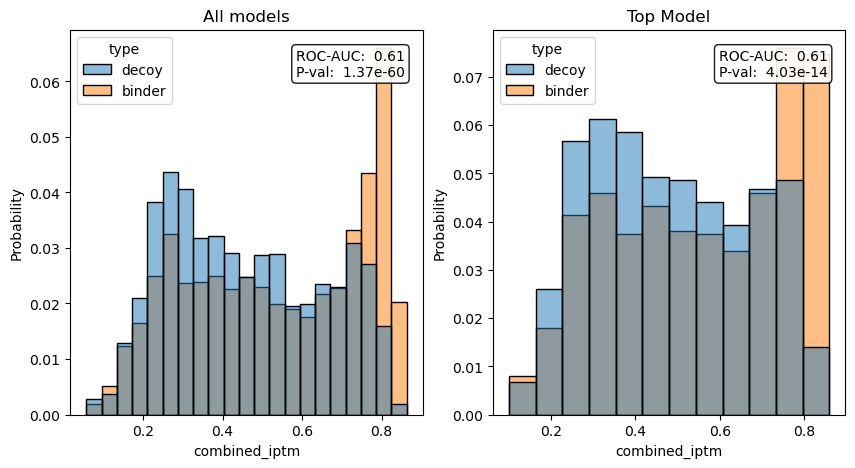

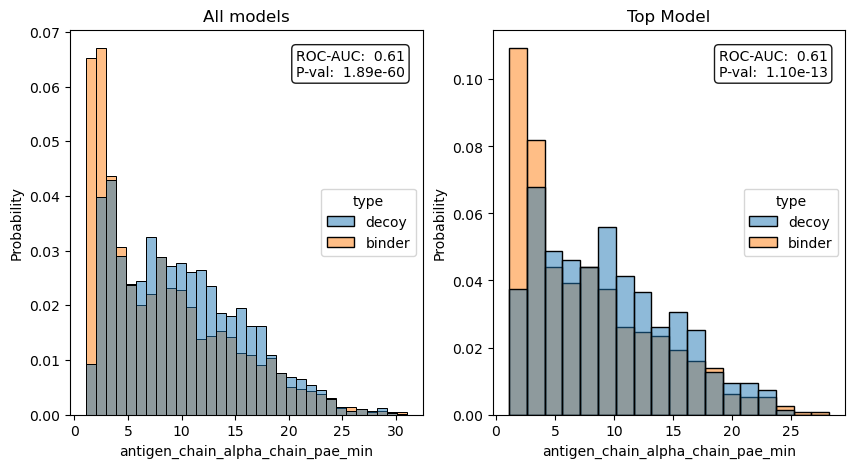

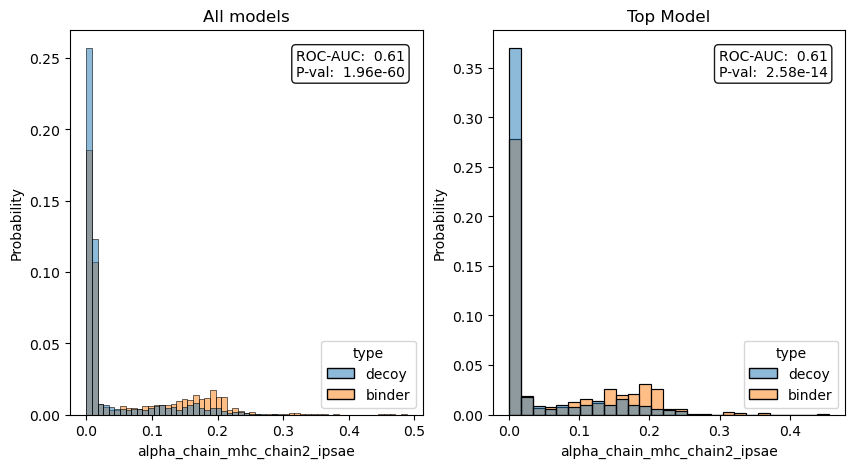

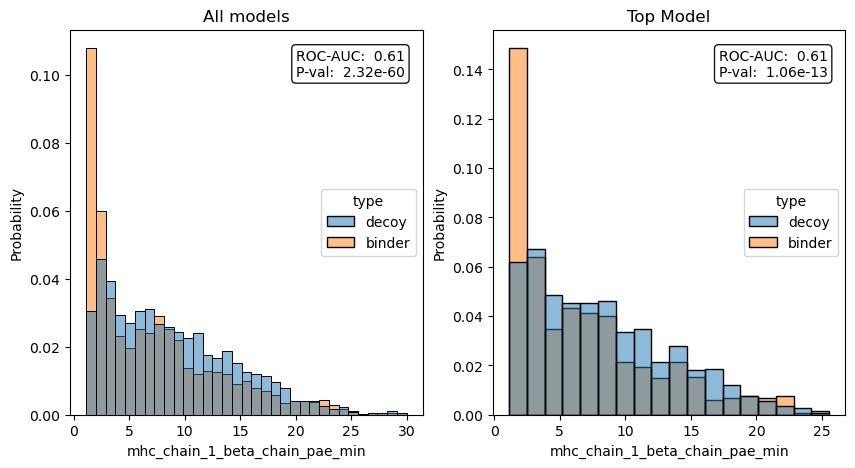

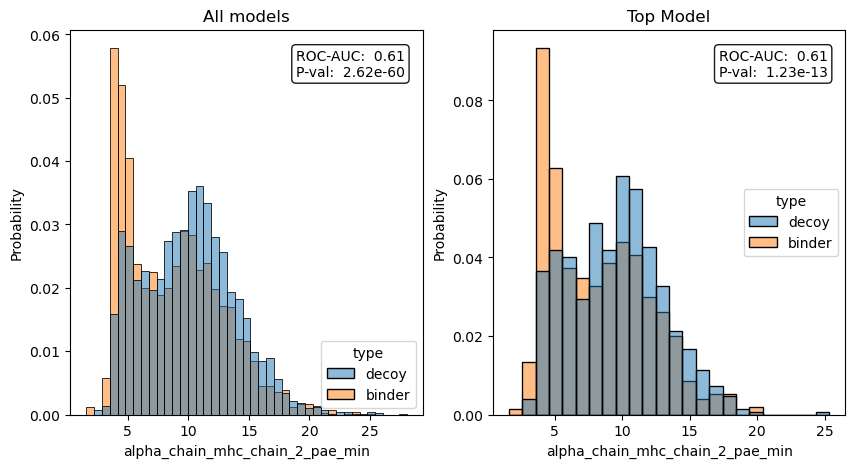

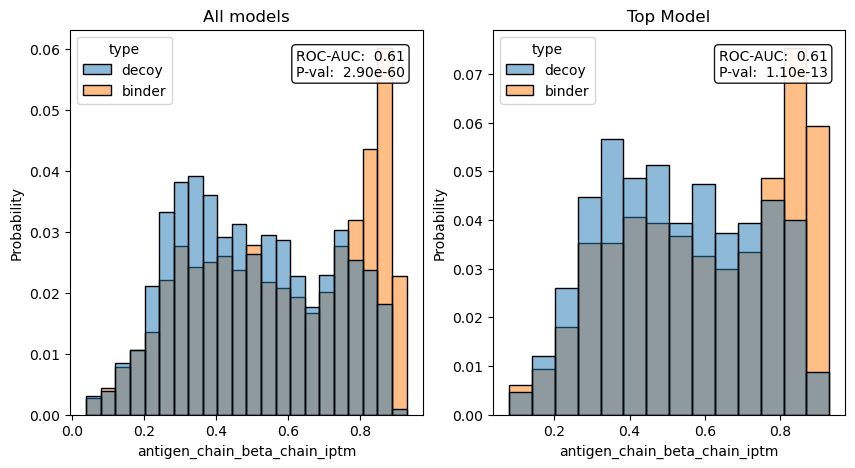

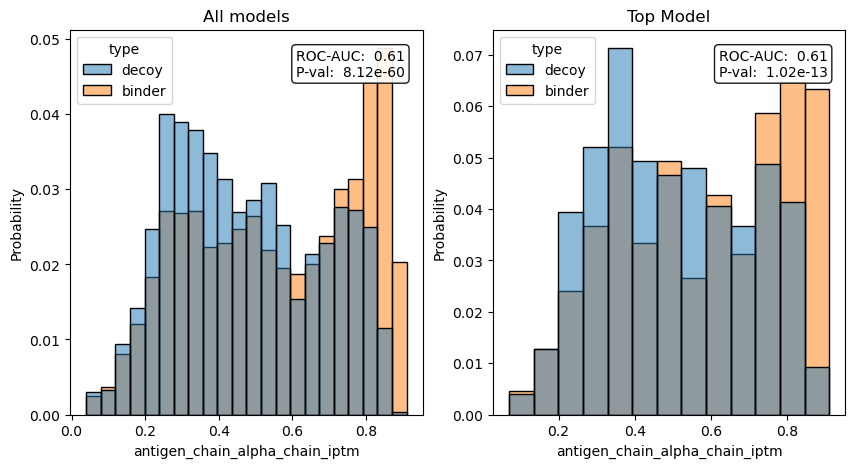

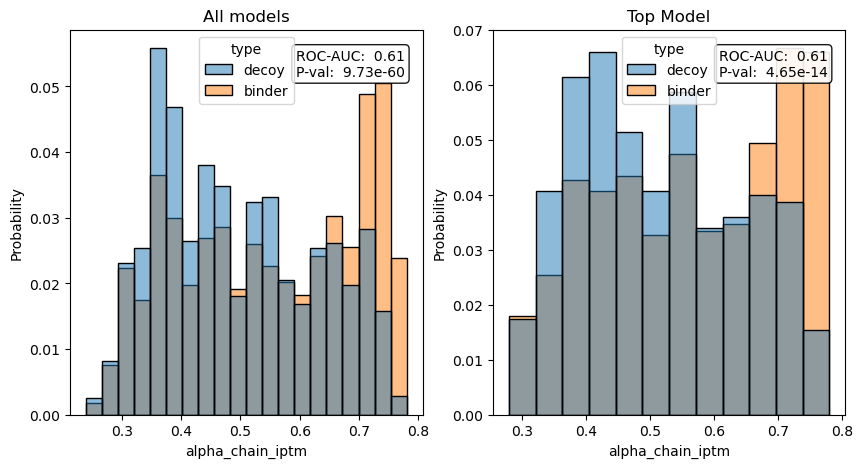

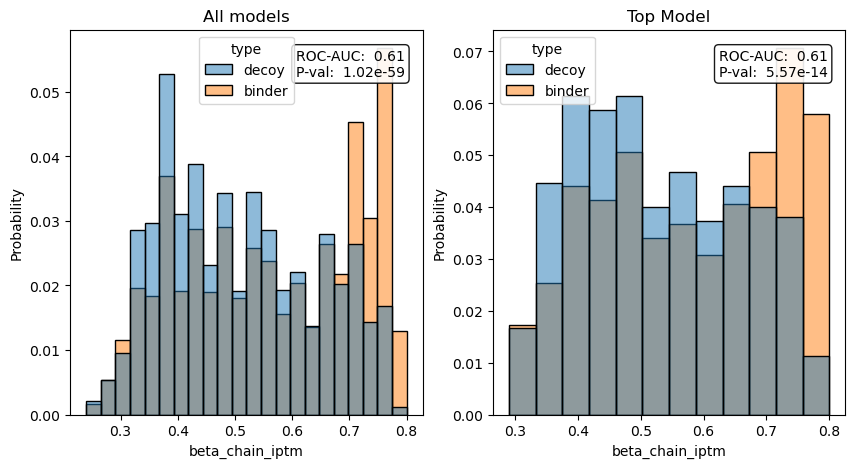

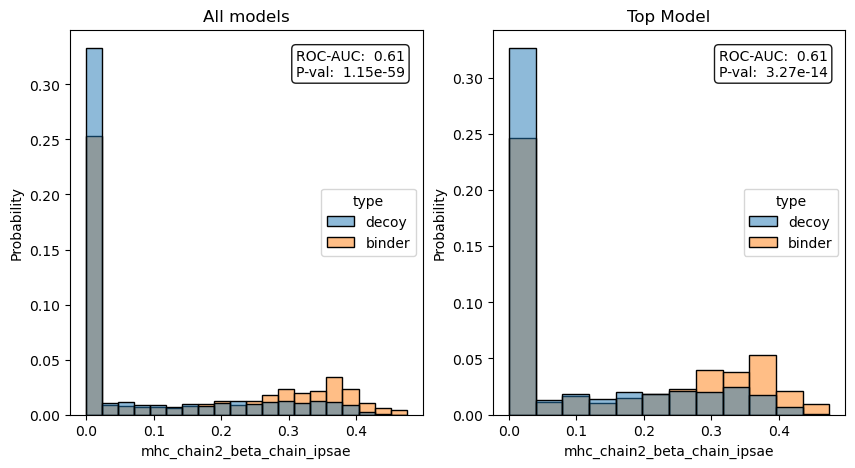

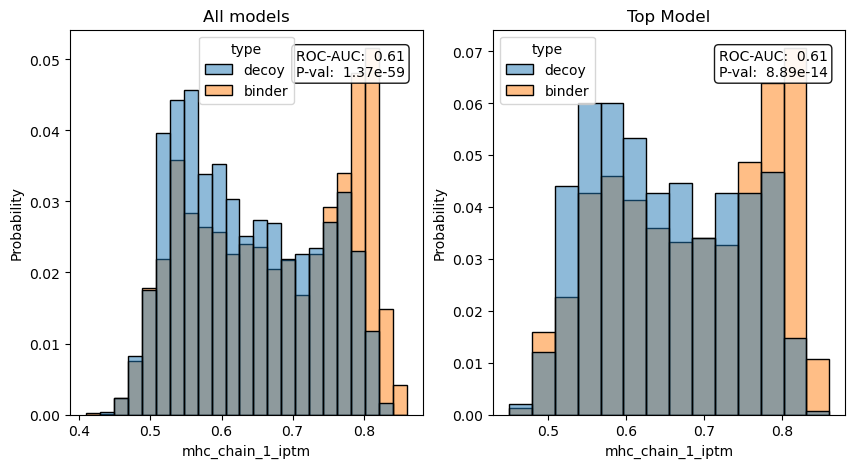

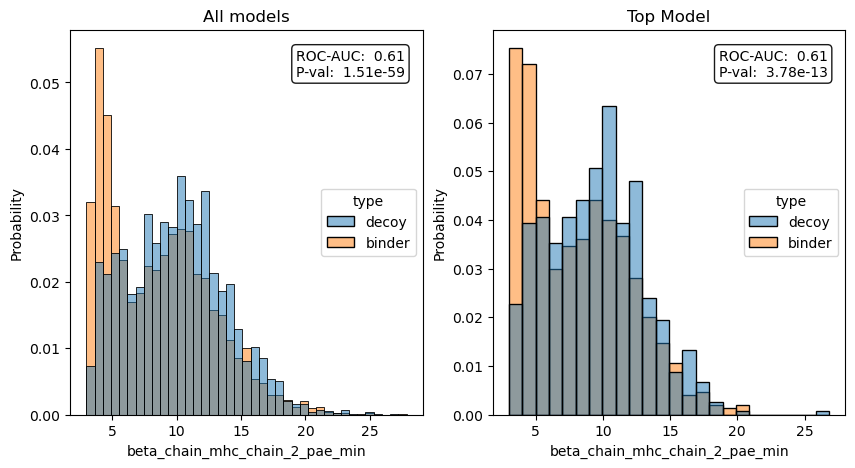

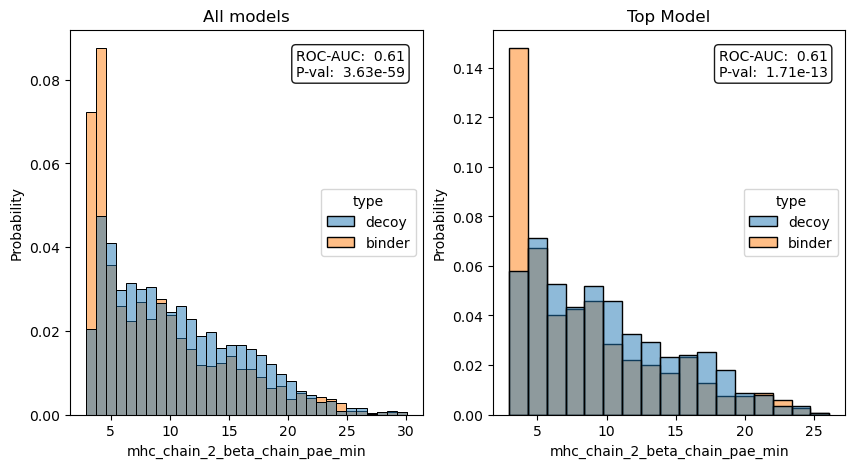

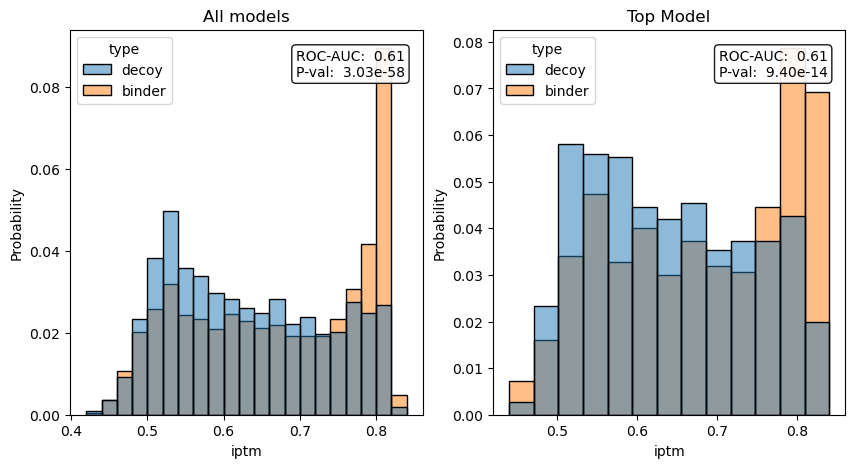

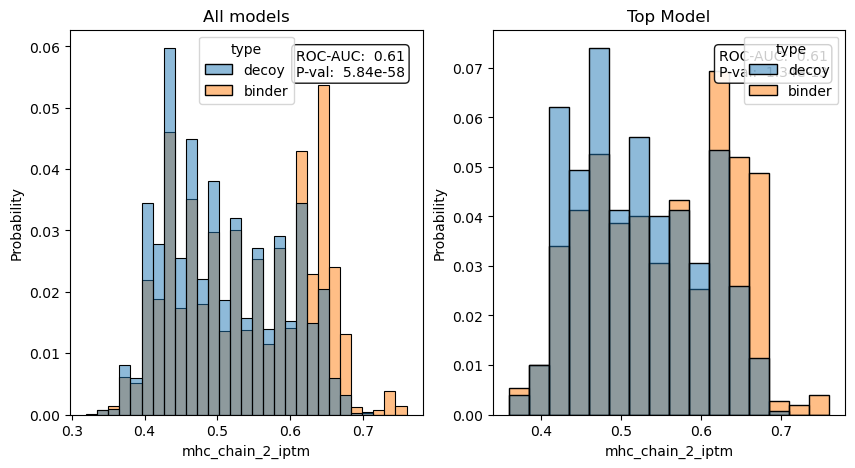

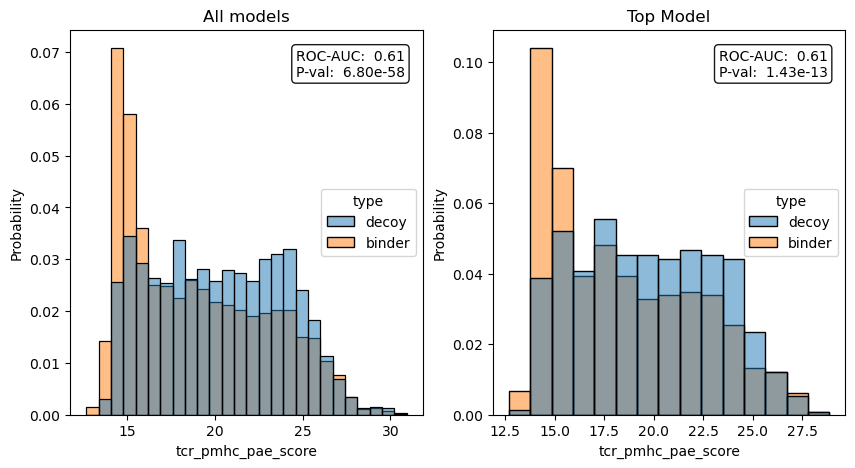

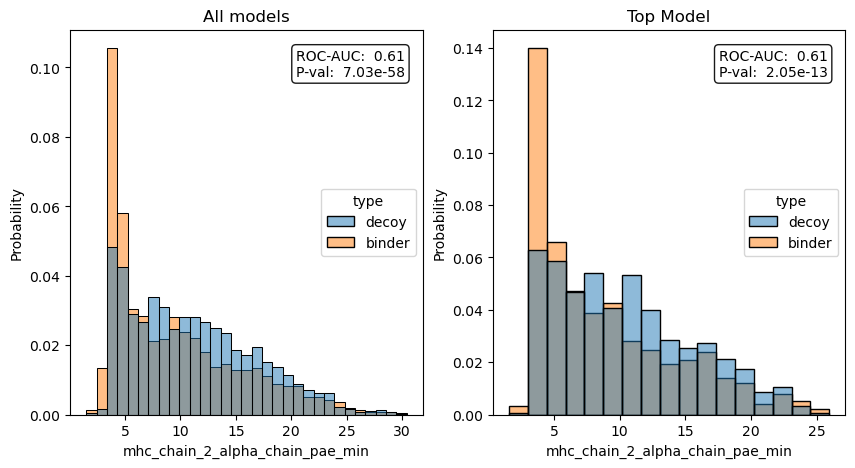

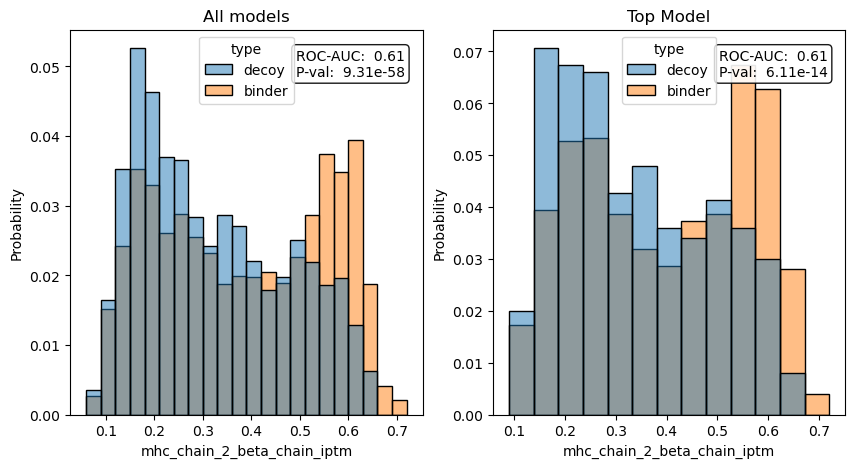

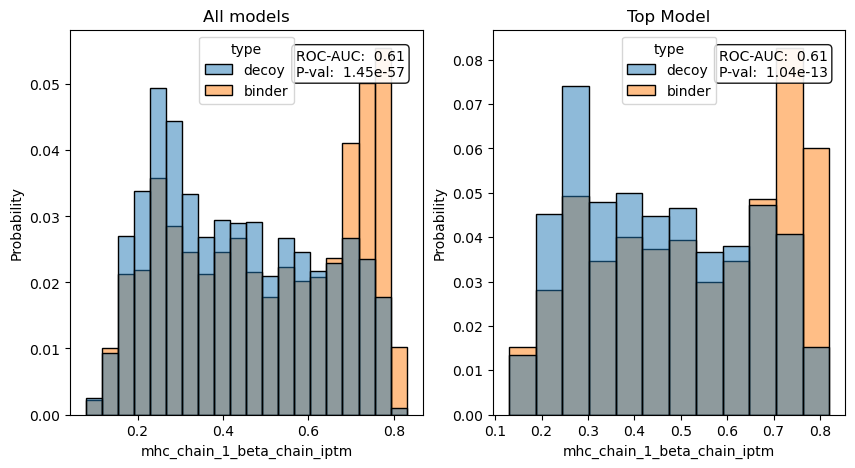

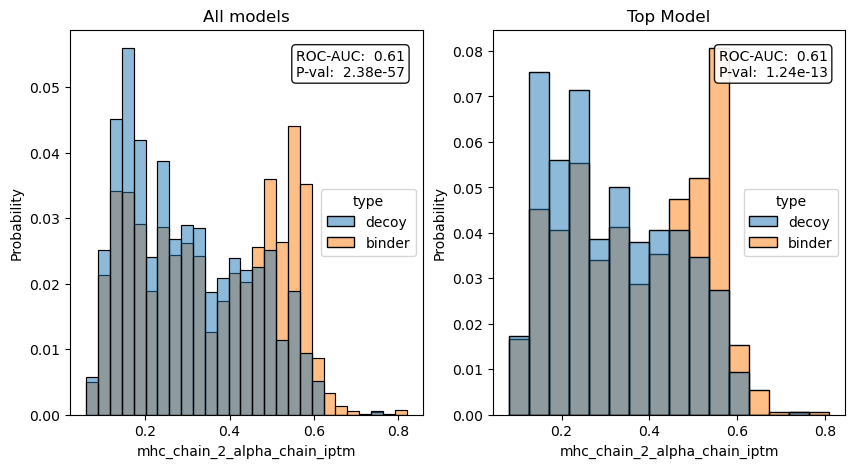

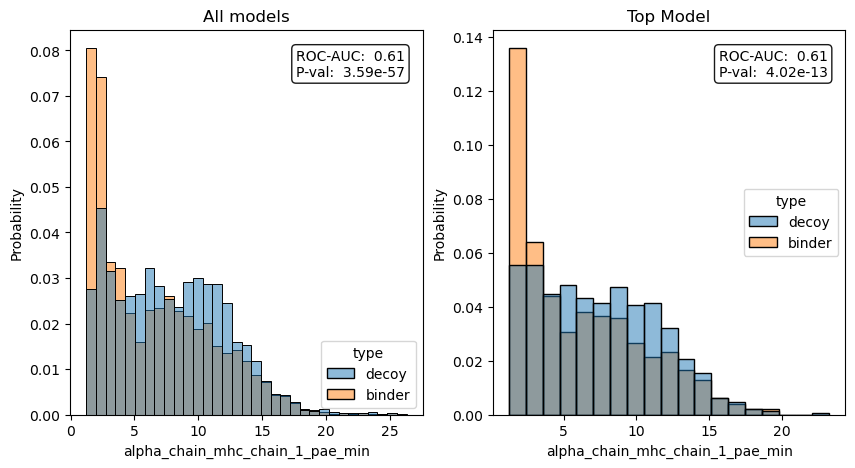

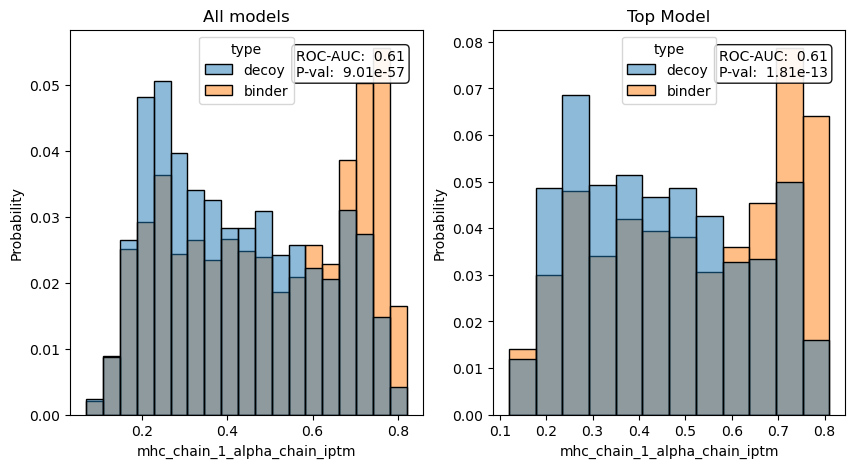

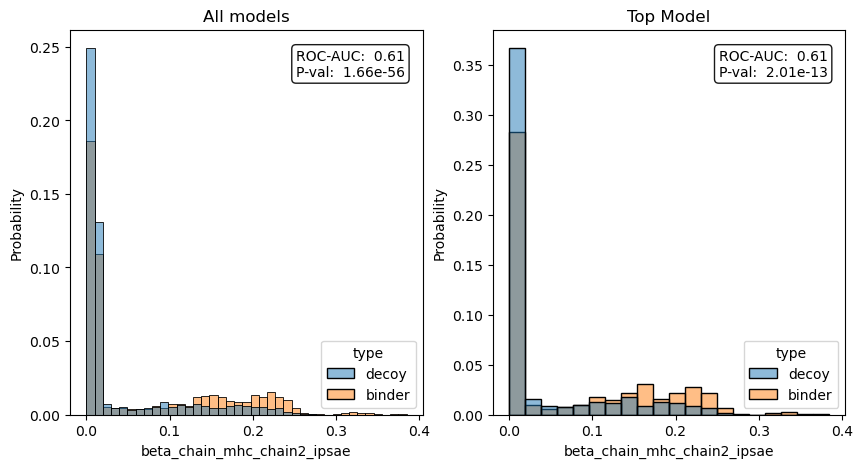

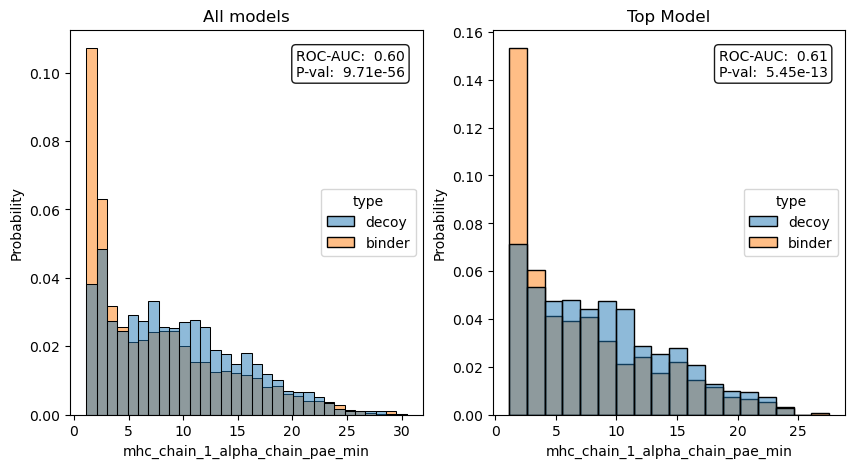

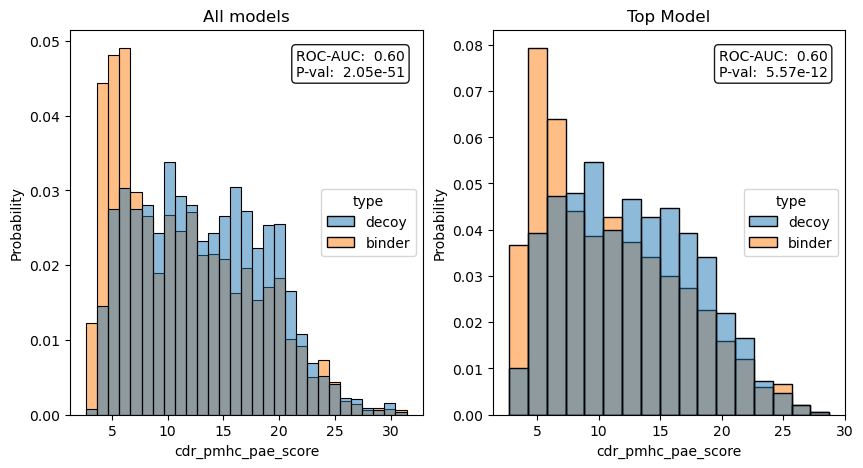

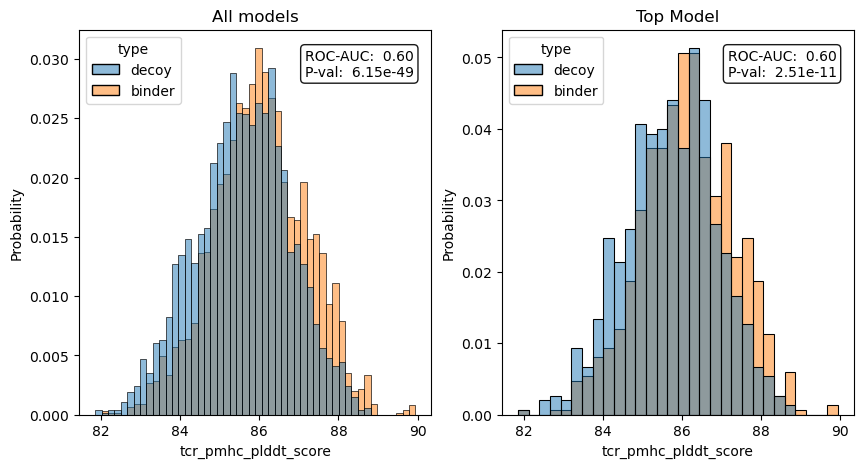

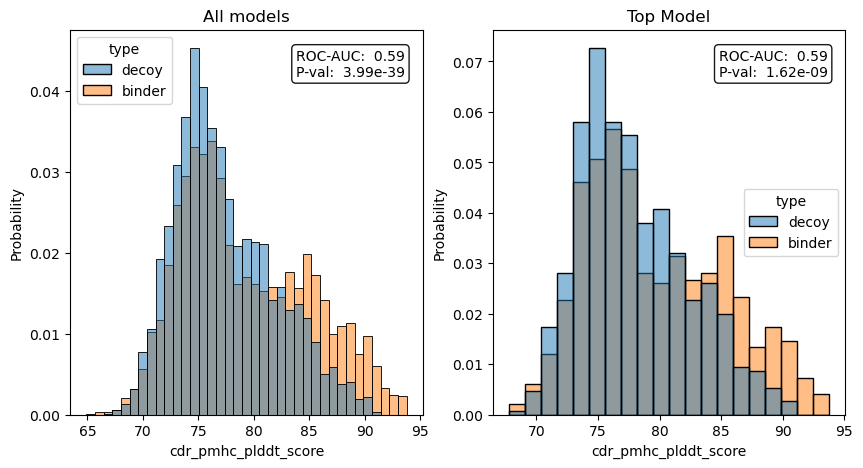

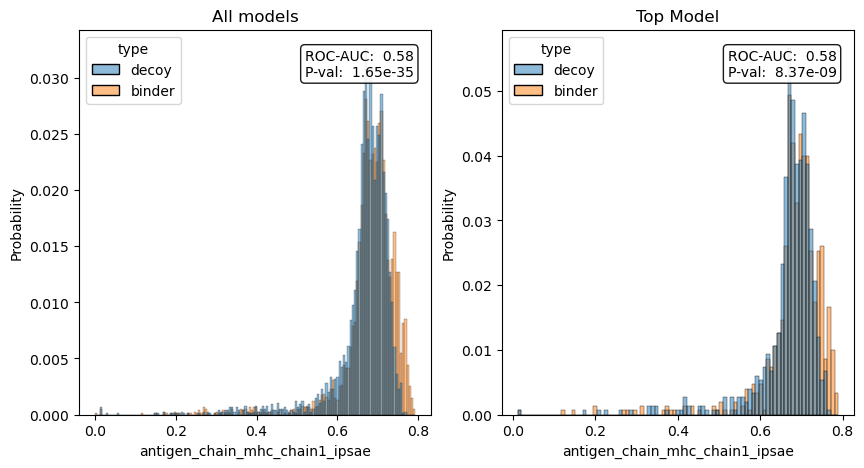

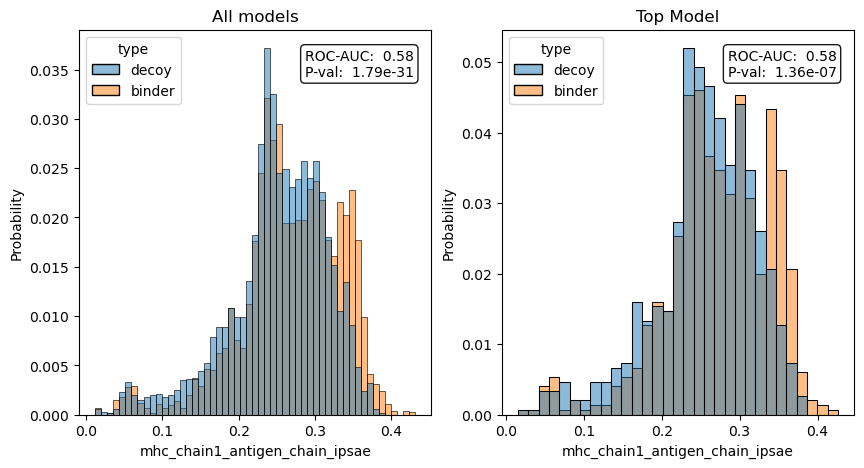

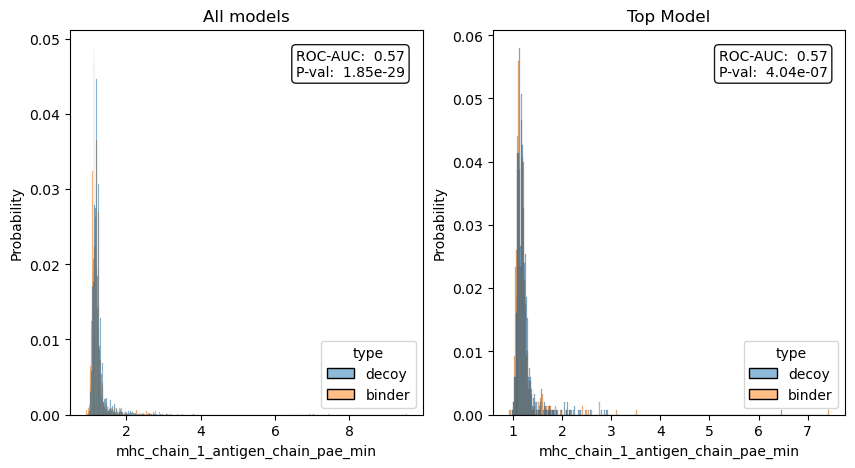

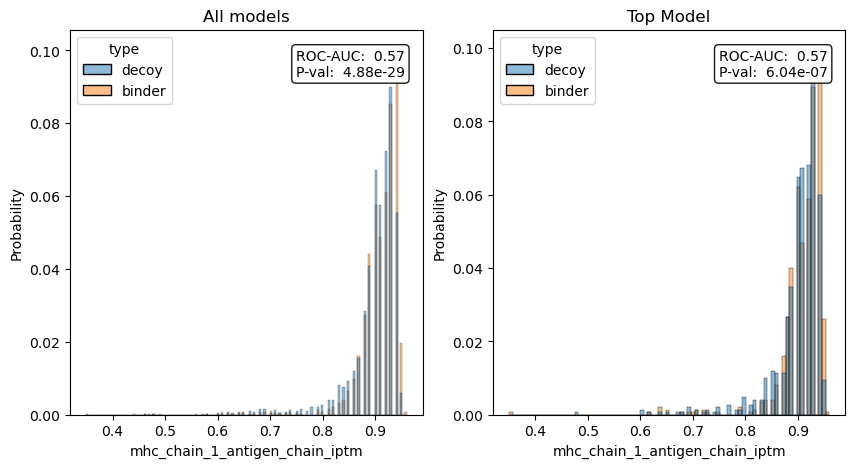

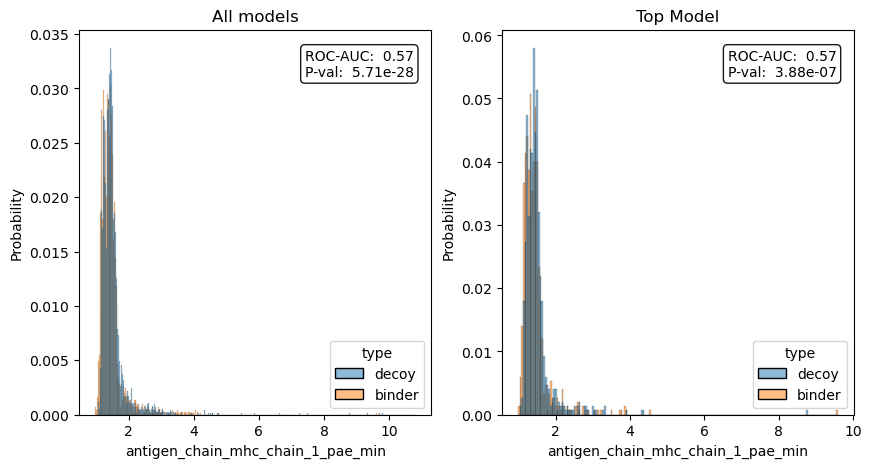

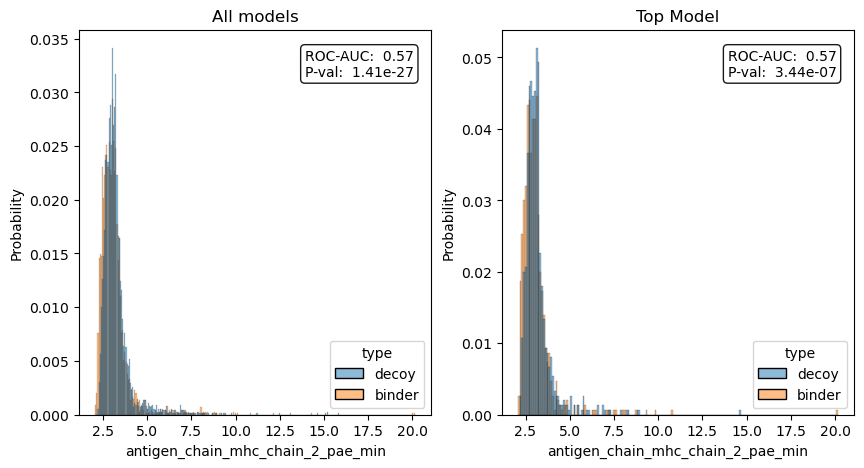

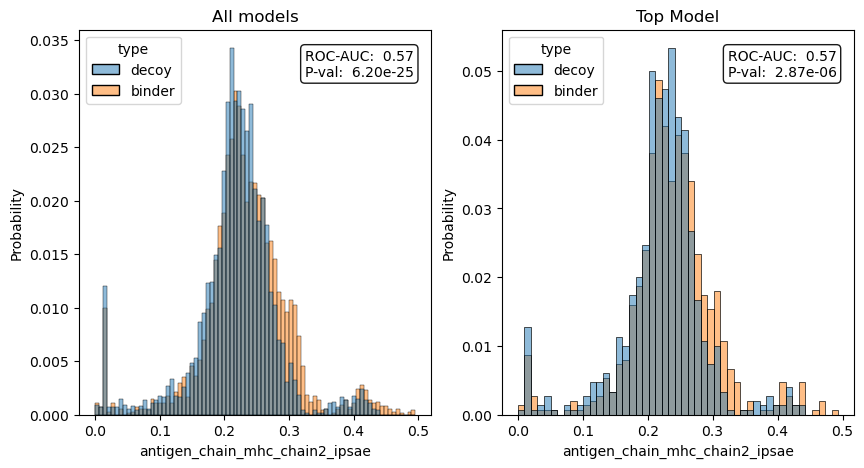

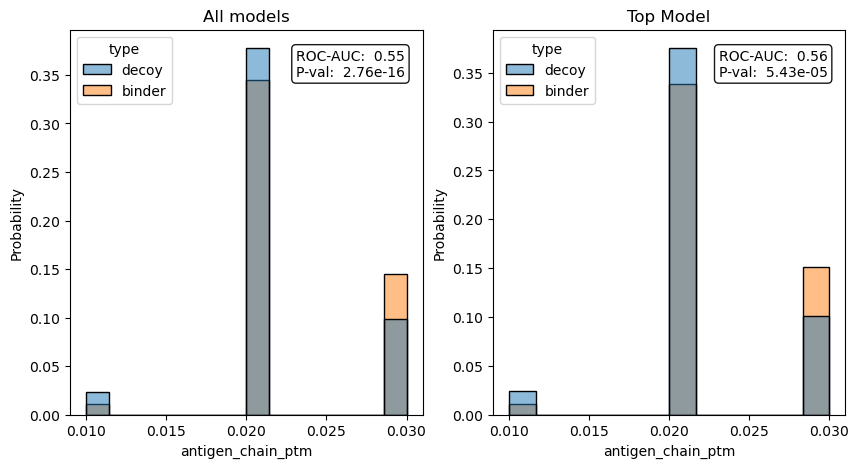

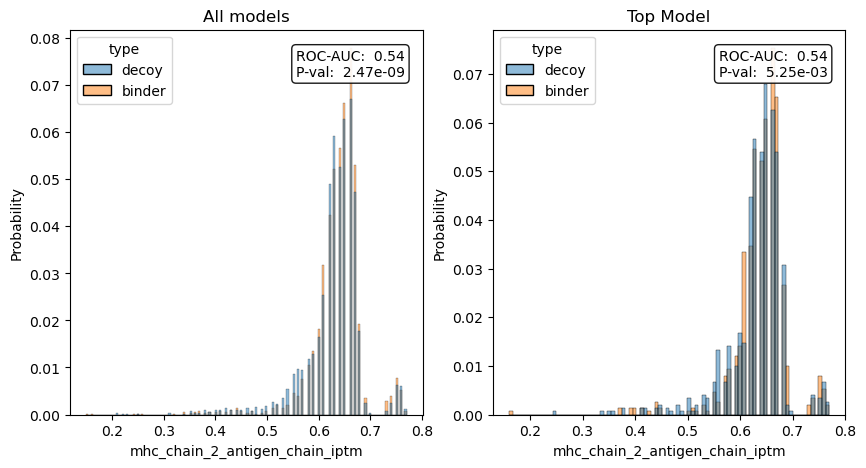

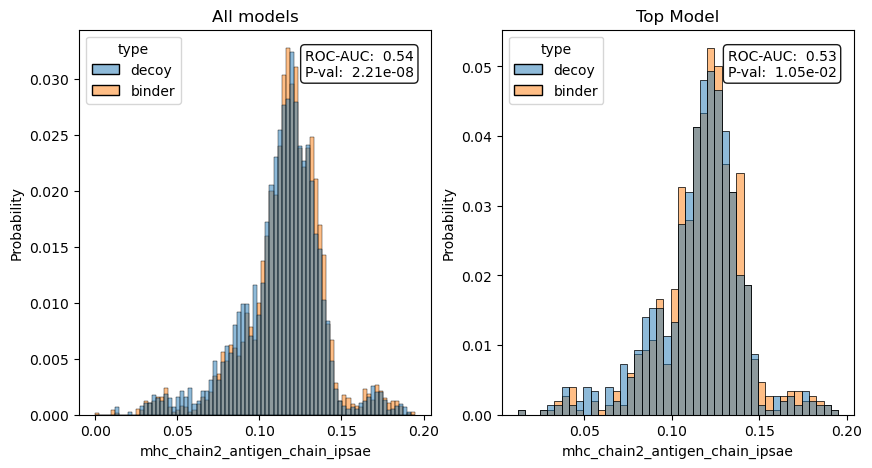

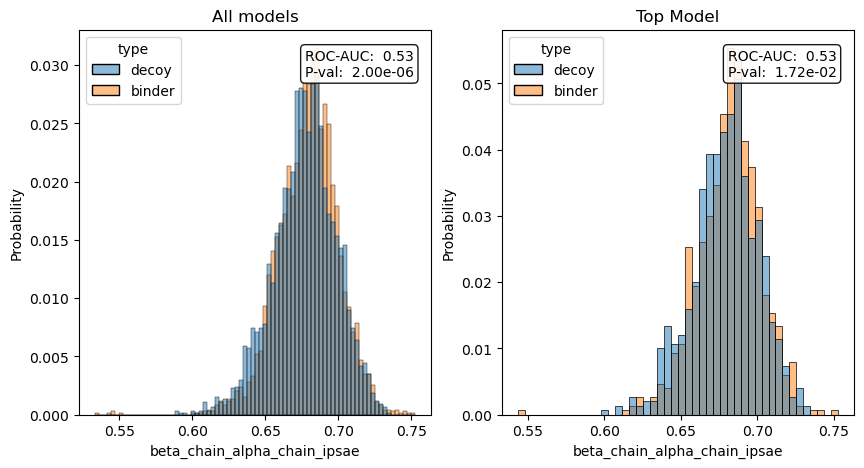

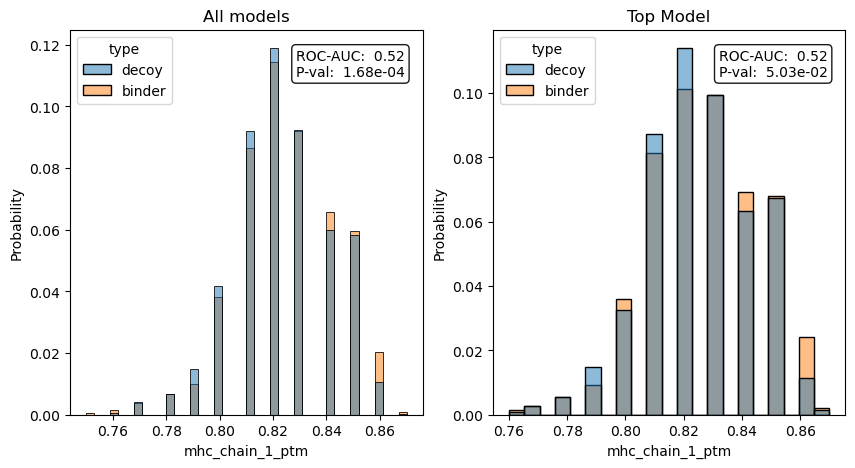

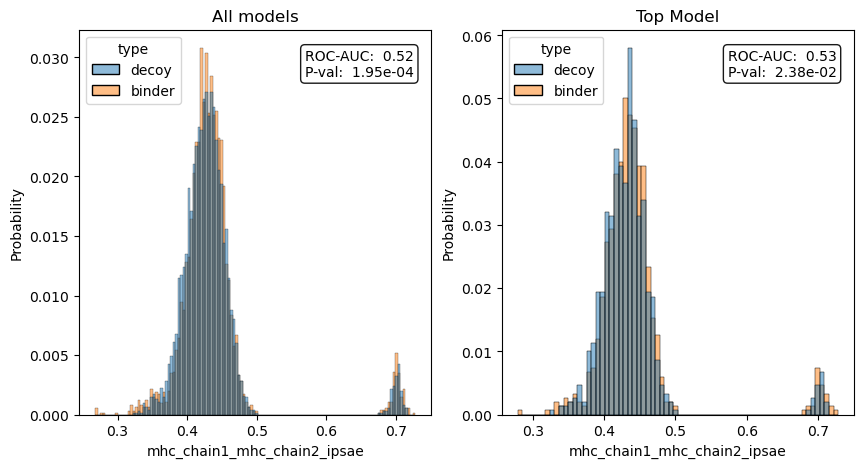

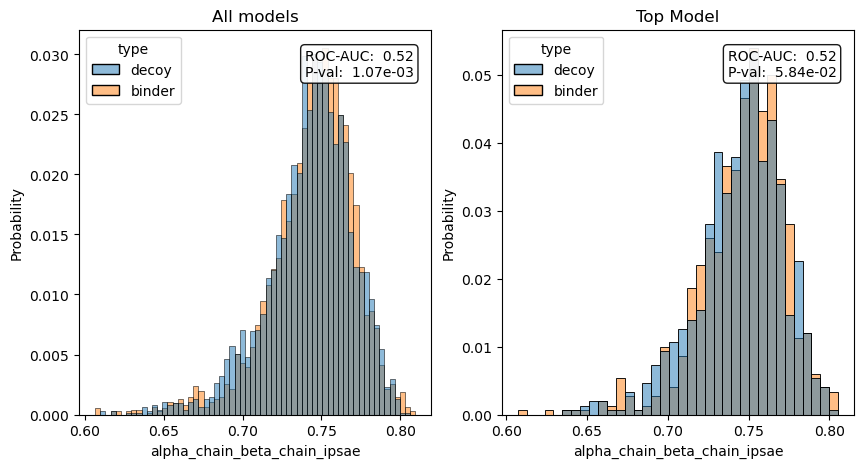

In [9]:
for column_name, row in (
    scores_summary.sort_values('roc_all_models', ascending=False).query('p_val_all_models < 0.05').iterrows()
):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    # All Models
    sns.histplot(af3_scores, x=column_name, hue='type', stat='probability', ax=ax1)
    ax1.set_title('All models')
    ax1.text(
        0.95,
        0.95,
        f"ROC-AUC: {row['roc_all_models']: .2f}\nP-val: {row['p_val_all_models']: .2e}",
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    # Top Model
    sns.histplot(af3_scores.query('top_model'), x=column_name, hue='type', stat='probability', ax=ax2)
    ax2.text(
        0.95,
        0.95,
        f"ROC-AUC: {row['roc_top_model']: .2f}\nP-val: {row['p_val_top_model']: .2e}",
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )
    ax2.set_title('Top Model')

    plt.show()